## What Is PyTorch?

--> Open-source machine learning framework that accelerates the path from research to production

--> Developed primarily by Facebook AI (Meta) and introduced in 2016

--> Today one of the two dominant deep learning frameworks, widely used in both academia and industry


## Why PyTorch Performs Well ?


--> Tensor data structure, CPU/GPU operators, and automatic differentiation are implemented in efficient C++

--> A strict separation is kept between the two — Python drives control flow

--> Control flow stays in Python, while optimized C++ code executes on the host CPU/GPU


## Install Pytorch

https://pytorch.org/get-started/locally/

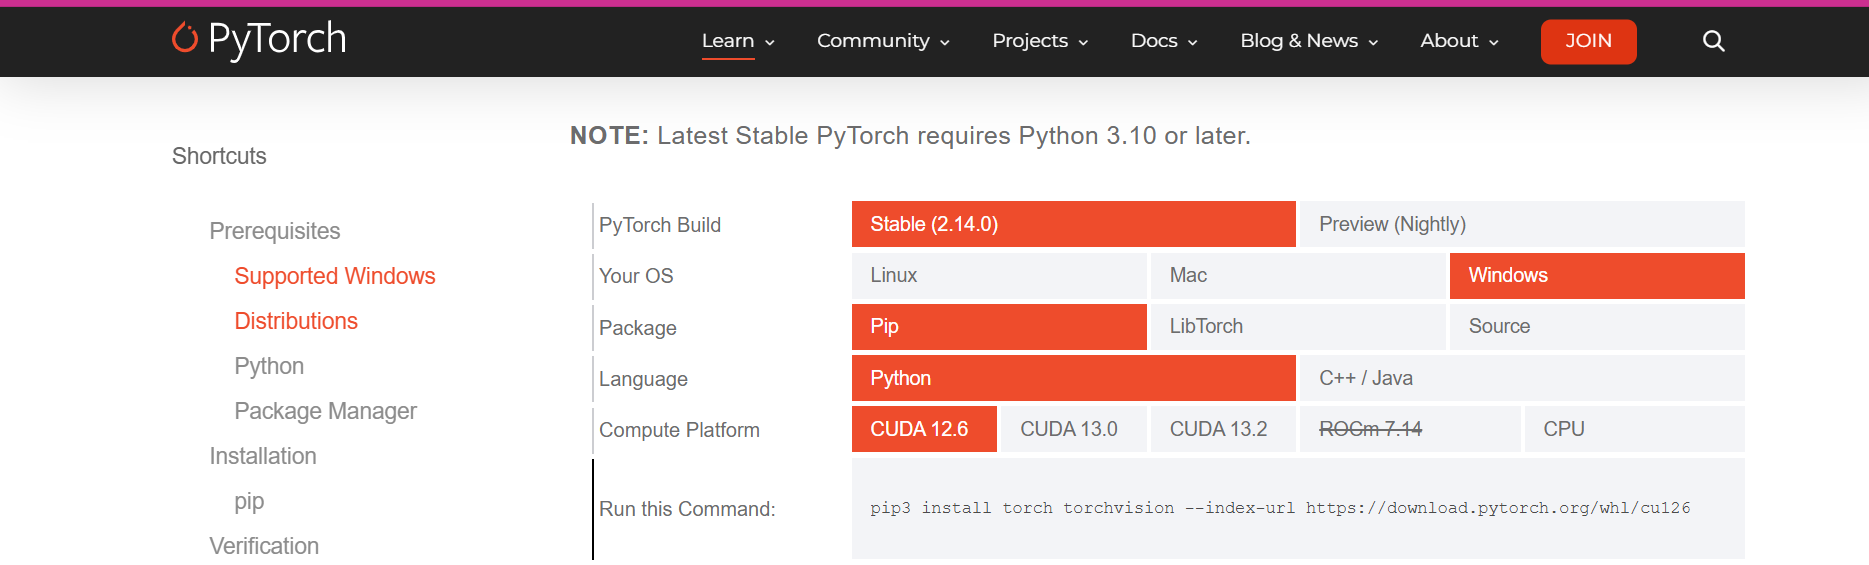

## Pytorch Basics

In [2]:
import torch
print("Torch version is", torch.__version__)

Torch version is 2.8.0+cu126


### Tensors

Tensors are the PyTorch equivalent to Numpy arrays, with the addition to also have support for GPU acceleration (more on that later).
The name "tensor" is a generalization of concepts you already know. For instance, a vector is a 1-D tensor, and a matrix a 2-D tensor. When working with neural networks, we will use tensors of various shapes and number of dimensions.

In [16]:
# Create a tensor from a (nested) list
x = torch.Tensor([[1, 2], [3, 4]])
print(x)

tensor([[1., 2.],
        [3., 4.]])


In [7]:
# torch.tensor (shape of tensor)
x = torch.Tensor(2, 3, 4)
print(x)

tensor([[[-9.2203e+15,  1.3677e-42,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]]])


In [8]:
# every run will print same values
torch.manual_seed(42) # Setting the seed

In [11]:
x = torch.Tensor(2, 3, 4)
print(x)

tensor([[[-9.2221e+15,  1.3677e-42,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]]])


In [22]:
em = torch.empty(2,3)
print(em)

tensor([[-9.2202e+15,  1.3677e-42,  2.3694e-38],
        [ 2.3694e-38,  2.3694e-38,  2.3694e-38]])


In [12]:
# `torch.zeros`: Creates a tensor filled with zeros
z = torch.zeros(2,3,1)
print(z)


tensor([[[0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.]]])


In [13]:
# `torch.ones`: Creates a tensor filled with ones
o = torch.ones(2,3,1)
print(o)


tensor([[[1.],
         [1.],
         [1.]],

        [[1.],
         [1.],
         [1.]]])


In [14]:
# `torch.rand`: Creates a tensor with random values uniformly sampled between 0 and 1
r = torch.rand(2,3,1)
print(r)


tensor([[[0.8823],
         [0.9150],
         [0.3829]],

        [[0.9593],
         [0.3904],
         [0.6009]]])


In [15]:
# `torch.randn`: Creates a tensor with random values sampled from a normal distribution with mean 0 and variance 1
rn = torch.randn(2,3,1)
print(rn)


tensor([[[ 1.1561],
         [ 0.3965],
         [-2.4661]],

        [[ 0.3623],
         [ 0.3765],
         [-0.1808]]])


In [21]:
# `torch.arange`: Creates a tensor containing the values $N,N+1,N+2,...,M$
A = torch.arange(2,100,5)   # (start , end , step)
print(A)


tensor([ 2,  7, 12, 17, 22, 27, 32, 37, 42, 47, 52, 57, 62, 67, 72, 77, 82, 87,
        92, 97])


In [26]:
# Tensors can be converted to numpy arrays, and numpy arrays back to tensors.
import numpy as np
np_arr = np.array([[1, 2], [3, 4]])
tensor = torch.from_numpy(np_arr)

print("Numpy array:", np_arr)
print("PyTorch tensor:", tensor)

Numpy array: [[1 2]
 [3 4]]
PyTorch tensor: tensor([[1, 2],
        [3, 4]])


In [27]:
# To transform a PyTorch tensor back to a numpy array
tensor = torch.arange(4)
np_arr = tensor.numpy()

print("PyTorch tensor:", tensor)
print("Numpy array:", np_arr)

PyTorch tensor: tensor([0, 1, 2, 3])
Numpy array: [0 1 2 3]




Note:
The conversion of tensors to numpy require the tensor to be on the CPU, and not the GPU (more on GPU support in a later section). In case you have a tensor on GPU, you need to call `.cpu()` on the tensor beforehand. Hence, you get a line like `np_arr = tensor.cpu().numpy()`.

In [24]:
x = torch.randn(2,3,4)
shape = x.shape
print("Shape:", x.shape)

size = x.size()
print("Size:", size)

Shape: torch.Size([2, 3, 4])
Size: torch.Size([2, 3, 4])


In [28]:
#using torch.*_like() methods:   
#torch.empty_like(another_tensor)   
#torch.zeros_like(another_tensor)      
#torch.rand_like(another_tensor)   

y = torch.ones_like(x)
print(y)

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])


In [31]:
x1 = torch.rand(2, 3)
x2 = torch.rand(2, 3)
y = x1 + x2

print("X1", x1)
print("\n")
print("X2", x2)
print("\n")
print("Y", y)

X1 tensor([[0.7653, 0.2979, 0.8035],
        [0.3813, 0.7860, 0.1115]])


X2 tensor([[0.2477, 0.6524, 0.6057],
        [0.3725, 0.7980, 0.8399]])


Y tensor([[1.0130, 0.9503, 1.4092],
        [0.7539, 1.5841, 0.9514]])


In [32]:
#in-place operations that are applied directly on the memory of a tensor. 
#We therefore change the values of `x2` without the chance to re-accessing the values of `x2` before the operation. 

x1 = torch.rand(2, 3)
x2 = torch.rand(2, 3)
print("X1 (before)", x1)
print("\n")
print("X2 (before)", x2)
print("\n")
print("\n")

x2.add_(x1)
print("X1 (after)", x1)
print("\n")
print("X2 (after)", x2)

X1 (before) tensor([[0.1374, 0.2331, 0.9578],
        [0.3313, 0.3227, 0.0162]])


X2 (before) tensor([[0.2137, 0.6249, 0.4340],
        [0.1371, 0.5117, 0.1585]])




X1 (after) tensor([[0.1374, 0.2331, 0.9578],
        [0.3313, 0.3227, 0.0162]])


X2 (after) tensor([[0.3511, 0.8580, 1.3918],
        [0.4683, 0.8345, 0.1747]])


In [75]:
x = torch.arange(6)
print("X", x)

X tensor([0, 1, 2, 3, 4, 5])


In [76]:
# Reshaping
# must have same number of elements
x_ = x.view(2, 3)
print("Reshaped X", x_)

Reshaped X tensor([[0, 1, 2],
        [3, 4, 5]])


In [77]:
x__ = x.reshape(3,2)
print("Reshaped X", x__)

Reshaped X tensor([[0, 1],
        [2, 3],
        [4, 5]])


In [35]:
# Swapping dimension 0 and 1
x = x.permute(1, 0) 
print("X", x)

X tensor([[0, 3],
        [1, 4],
        [2, 5]])


In [51]:
x = torch.arange(6)
x = x.view(2, 3)
print("X", x)
print(x.size())

X tensor([[0, 1, 2],
        [3, 4, 5]])
torch.Size([2, 3])


In [52]:
W = torch.arange(9).view(3, 3) # We can also stack multiple operations in a single line
print("W", W)

W tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]])


In [53]:
# Matrix multiplication
h = torch.matmul(x, W) 
print("h", h)

h tensor([[15, 18, 21],
        [42, 54, 66]])


In [54]:
# another way for Matrix multiplication
h2 = x @ W
print(h2)

tensor([[15, 18, 21],
        [42, 54, 66]])


#### Indexing

We often have the situation where we need to select a part of a tensor. Indexing works just like in numpy, so let's try it:

In [64]:
x = torch.arange(12).view(3, 4)
print("X", x)

X tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])


In [65]:
print(x[:, 1])   # Second column

tensor([1, 5, 9])


In [66]:
print(x[0])      # First row

tensor([0, 1, 2, 3])


In [67]:
print(x[:2, -1]) # First two rows, last column

tensor([3, 7])


In [68]:
print(x[1:3, :]) # Middle two rows

tensor([[ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])


## GPU Support

Graphics Processing Unit. 

A GPU can perform many thousands of small operations in parallel, making it very well suitable for performing large matrix operations in neural networks.

In [85]:
gpu_avail = torch.cuda.is_available()
print(f"Is the GPU available? {gpu_avail}")

Is the GPU available? True


In [87]:
# take object which point to GPU then write code respect to your device object
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("Device", device)

Device cuda


In [88]:
# create tensor on GPU
x = torch.zeros(2, 3)
x = x.to(device)
print("X", x)

X tensor([[0., 0., 0.],
        [0., 0., 0.]], device='cuda:0')


In [95]:
import time

x = torch.randn(5000, 5000)

## CPU version
start_time = time.time()
_ = torch.matmul(x, x)
end_time = time.time()
print(f"CPU time: {(end_time - start_time):6.5f}s")



CPU time: 0.40202s


In [96]:
## GPU version
x = x.to(device)
_ = torch.matmul(x, x)  # First operation to 'burn in' GPU
# CUDA is asynchronous, so we need to use different timing functions
start = torch.cuda.Event(enable_timing=True)
end = torch.cuda.Event(enable_timing=True)
start.record()
_ = torch.matmul(x, x)
end.record()
torch.cuda.synchronize()  # Waits for everything to finish running on the GPU
print(f"GPU time: {0.001 * start.elapsed_time(end):6.5f}s")  # Milliseconds to seconds

GPU time: 0.05676s


In [97]:
# GPU operations have a separate seed we also want to set
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# Additionally, some operations on a GPU are implemented stochastic for efficiency
# We want to ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False